In [9]:
import matplotlib.pyplot as plt
import pandas as pd

In [13]:
def results(path):
    # One row per number of workers: median times, speedup and efficiency.
    runs = pd.read_csv(path)
    table = runs.groupby("workers")[["pool_start_s", "compute_wall_s", "total_s"]].median()
    table["speedup"] = table["total_s"].iloc[0] / table["total_s"]
    table["efficiency"] = table["speedup"] / table.index
    return table.round(2)

def amdahl(s, n):
    return 1 / (s + (1 - s) / n)

def chart(table, color, label = ""):
    s = table["pool_start_s"].iloc[0] / table["total_s"].iloc[0]
    n = table.index
    plt.plot(n, n, "--", color="#898781", label="ideal")
    plt.plot(n, amdahl(s, n), color="#c3c2b7", linewidth=3, label=f"Amdahl, s = {s:.1%}")
    plt.plot(n, table["speedup"], "o-", color=color, label=f"measured {label}")
    plt.xscale("log", base=2)
    plt.xticks(n, n)
    plt.xlabel("workers")
    plt.ylabel("speedup")
    plt.legend()
    print(f"serial part s = {s:.1%}: the speedup can never exceed {1 / s:.1f}")

def serial_fraction(table):
    n = table.index[1:]
    S = table["speedup"].iloc[1:]
    return ((1 / S - 1 / n) / (1 - 1 / n)).round(3)


In [ ]:

compute = results("..\\results\\scaling-30212.csv")
compute

serial_fraction(compute)

workers
2     0.010
4     0.009
8     0.006
16    0.006
dtype: float64

serial part s = 0.2%: the speedup can never exceed 474.9


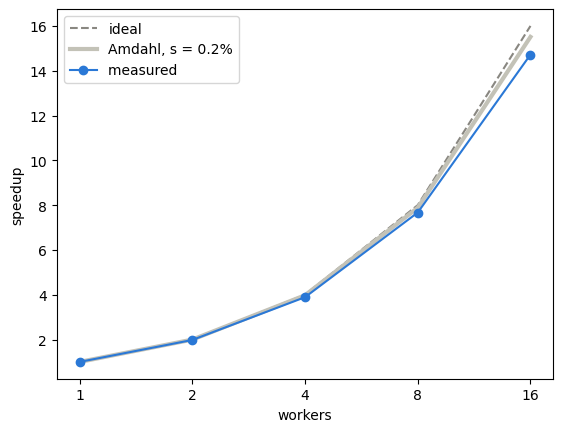

In [15]:
chart(compute, "#2a78d6")